In [1]:
import os
import sys

sys.path.append("..")

import critical_loads as cl
import geopandas as gpd
import matplotlib.pyplot as plt
import nivapy3 as nivapy
import pandas as pd
import rioxarray as rio
from sqlalchemy import text

plt.style.use("ggplot")

# Exceedance calculations: October 2026

# Update deposition

Areti has added EMEP data to

    shared/common/icp_waters/deposition_data/gp_review_scenarios_2026

For this work, we are only interested in the **annual baseline** netCDF files for 2015, 2040 and 2050:

    shared/common/icp_waters/deposition_data/gp_review_scenarios_2026/annual_scenario_simulations_5_year_average/EMEP01_annual_baseline2015_5year_average.nc
    shared/common/icp_waters/deposition_data/gp_review_scenarios_2026/annual_scenario_simulations_5_year_average/EMEP01_annual_baseline2040_5year_average.nc
    shared/common/icp_waters/deposition_data/gp_review_scenarios_2026/annual_scenario_simulations_5_year_average/EMEP01_annual_baseline2050_5year_average.nc

This notebook reads the data, calculates the average deposition for each EMEP 0.1 degree grid cell, and adds new deposition time series to the database.

In [2]:
# Connect to PostGIS
eng = nivapy.da.connect_postgis(admin=True)

Username:  ········
Password:  ········


Connection successful.


## 1. Read EMEP 0.1 degree grid

In [3]:
sql = text("SELECT * FROM deposition.dep_grid_0_1deg")
grid01 = gpd.read_postgis(sql, eng)
grid01["id"] = (
    (grid01["lat"] * 100).round().astype(int).astype(str).str.zfill(4)
    + (grid01["lon"] * 100).round().astype(int).astype(str).str.zfill(4)
).astype(int)
grid01.head()

,cell_id,lat,lon,area_m2,geom,id
0,62050675,62.05,6.75,5.830022e+07,"MULTIPOLYGON (((6.8 62, 6.7 62, 6.7 62.1, 6.8 ...",62050675
1,67951655,67.95,16.55,4.507216e+07,"MULTIPOLYGON (((16.6 68, 16.6 67.9, 16.5 67.9,...",67951655
2,60350595,60.35,5.95,6.151349e+07,"MULTIPOLYGON (((6 60.3, 5.9 60.3, 5.9 60.4, 6 ...",60350595
3,59350635,59.35,6.35,5.808014e+07,"MULTIPOLYGON (((6.4 59.30405, 6.4 59.3, 6.3783...",59350635
4,69842855,69.85,28.55,4.287583e+07,"MULTIPOLYGON (((28.6 69.8, 28.50925 69.8, 28.5...",69852855


## 2. Read EMEP data and add to database

In [4]:
def calculate_dep_totals(ds):
    """Takes an xarray netCDF dataset in the format used by EMEP and calculates
    grid average deposition totals:

        Total SOx = Wet SOx + Dry SOx
        Total OxN = Wet OxN + Dry OxN
        Total RedN = Wet RedN + Dry RedN
        Total N = Total OxN + Total RedN

    Args:
        ds: xarray dataset

    Returns:
        New variables are added to 'ds'.
    """
    # Pars of interest
    par_list = [
        "DDEP_SOX_m2Grid",
        "WDEP_SOX",
        "DDEP_OXN_m2Grid",
        "WDEP_OXN",
        "DDEP_RDN_m2Grid",
        "WDEP_RDN",
    ]

    # Check N units are consistent
    for par in par_list:
        unit = ds[par].attrs["units"]
        assert unit in ["mgS/m2", "mgN/m2"], "Units not consistent."

    # Calculate total oxidised S
    ds["DEP_SOX"] = ds["WDEP_SOX"] + ds["DDEP_SOX_m2Grid"]
    ds["DEP_SOX"].attrs["units"] = "mgS/m2"

    # Calculate total oxidised N
    ds["DEP_OXN"] = ds["WDEP_OXN"] + ds["DDEP_OXN_m2Grid"]
    ds["DEP_OXN"].attrs["units"] = "mgN/m2"

    # Calculate total reduced N
    ds["DEP_RDN"] = ds["WDEP_RDN"] + ds["DDEP_RDN_m2Grid"]
    ds["DEP_RDN"].attrs["units"] = "mgN/m2"

    # Calculate total N
    ds["DEP_TOTN"] = (
        ds["WDEP_OXN"] + ds["WDEP_RDN"] + ds["DDEP_OXN_m2Grid"] + ds["DDEP_RDN_m2Grid"]
    )
    ds["DEP_TOTN"].attrs["units"] = "mgN/m2"

    return ds

In [5]:
# GP review data from EMEP delivered October 2026
emep_dir = r"/home/jovyan/shared/common/icp_waters/deposition_data/gp_review_scenarios_2026/v7a_vcorr/annual_scenario_simulations_5_year_average"

pars = ["DEP_SOX", "DEP_OXN", "DEP_RDN"]
for idx, year in enumerate([2015, 2040, 2050]):
    # Read EMEP data
    nc_path = os.path.join(emep_dir, f"EMEP01_annual_baseline{year}_5year_average.nc")
    ds = rio.open_rasterio(nc_path, mask_and_scale=True)
    ds.rio.write_crs(4326, inplace=True)

    # Calculate dep totals
    ds = calculate_dep_totals(ds)[pars]

    # Convert to df and assign to 0.1 degree grid
    df = (
        ds.squeeze()
        .to_dataframe()[pars]
        .reset_index()
        .rename(columns={"y": "lat", "x": "lon"})
        .query("lon > 0")
    )
    df["id"] = (
        (df["lat"] * 100).round().astype(int).astype(str).str.zfill(4)
        + (df["lon"] * 100).round().astype(int).astype(str).str.zfill(4)
    ).astype(int)
    gdf = grid01.merge(df[["id"] + pars], how="left", on="id").drop(columns="id")

    assert gdf["DEP_SOX"].isna().sum() == 0

    # Build metadata for new dep series
    series_id = 68 + idx
    long_name = f"EMEP {year} GP-rev-2026"
    short_name = f"emep{year}GP2026"
    grid = "0_1deg"
    desc = "v7a EMEP scenarios. Delivered October 2026."

    # # Delete data if already exists
    # with eng.begin() as conn:
    #     for table in [
    #         "deposition.dep_values_0_1deg_grid",
    #         "deposition.dep_series_defs",
    #     ]:
    #         conn.execute(
    #             text(f"DELETE FROM {table} WHERE series_id = :series_id"),
    #             {"series_id": series_id},
    #         )

    # # Add new series
    # cl.add_dep_series(
    #     series_id,
    #     long_name,
    #     short_name,
    #     grid,
    #     desc,
    #     eng,
    # )

    # Prepare dep data for upload
    df = pd.DataFrame(gdf[["cell_id"] + pars])
    df = df.rename(columns={"DEP_RDN": 2, "DEP_OXN": 1, "DEP_SOX": 4})
    df = df.melt(id_vars="cell_id", var_name="param_id")
    df["series_id"] = series_id

    # # Upload
    # df.to_sql(
    #     "dep_values_0_1deg_grid",
    #     con=eng,
    #     schema="deposition",
    #     if_exists="append",
    #     index=False,
    #     method="multi",
    #     chunksize=1000,
    # )

Series added successfully.
Series added successfully.
Series added successfully.


## 3. Plot EMEP deposition

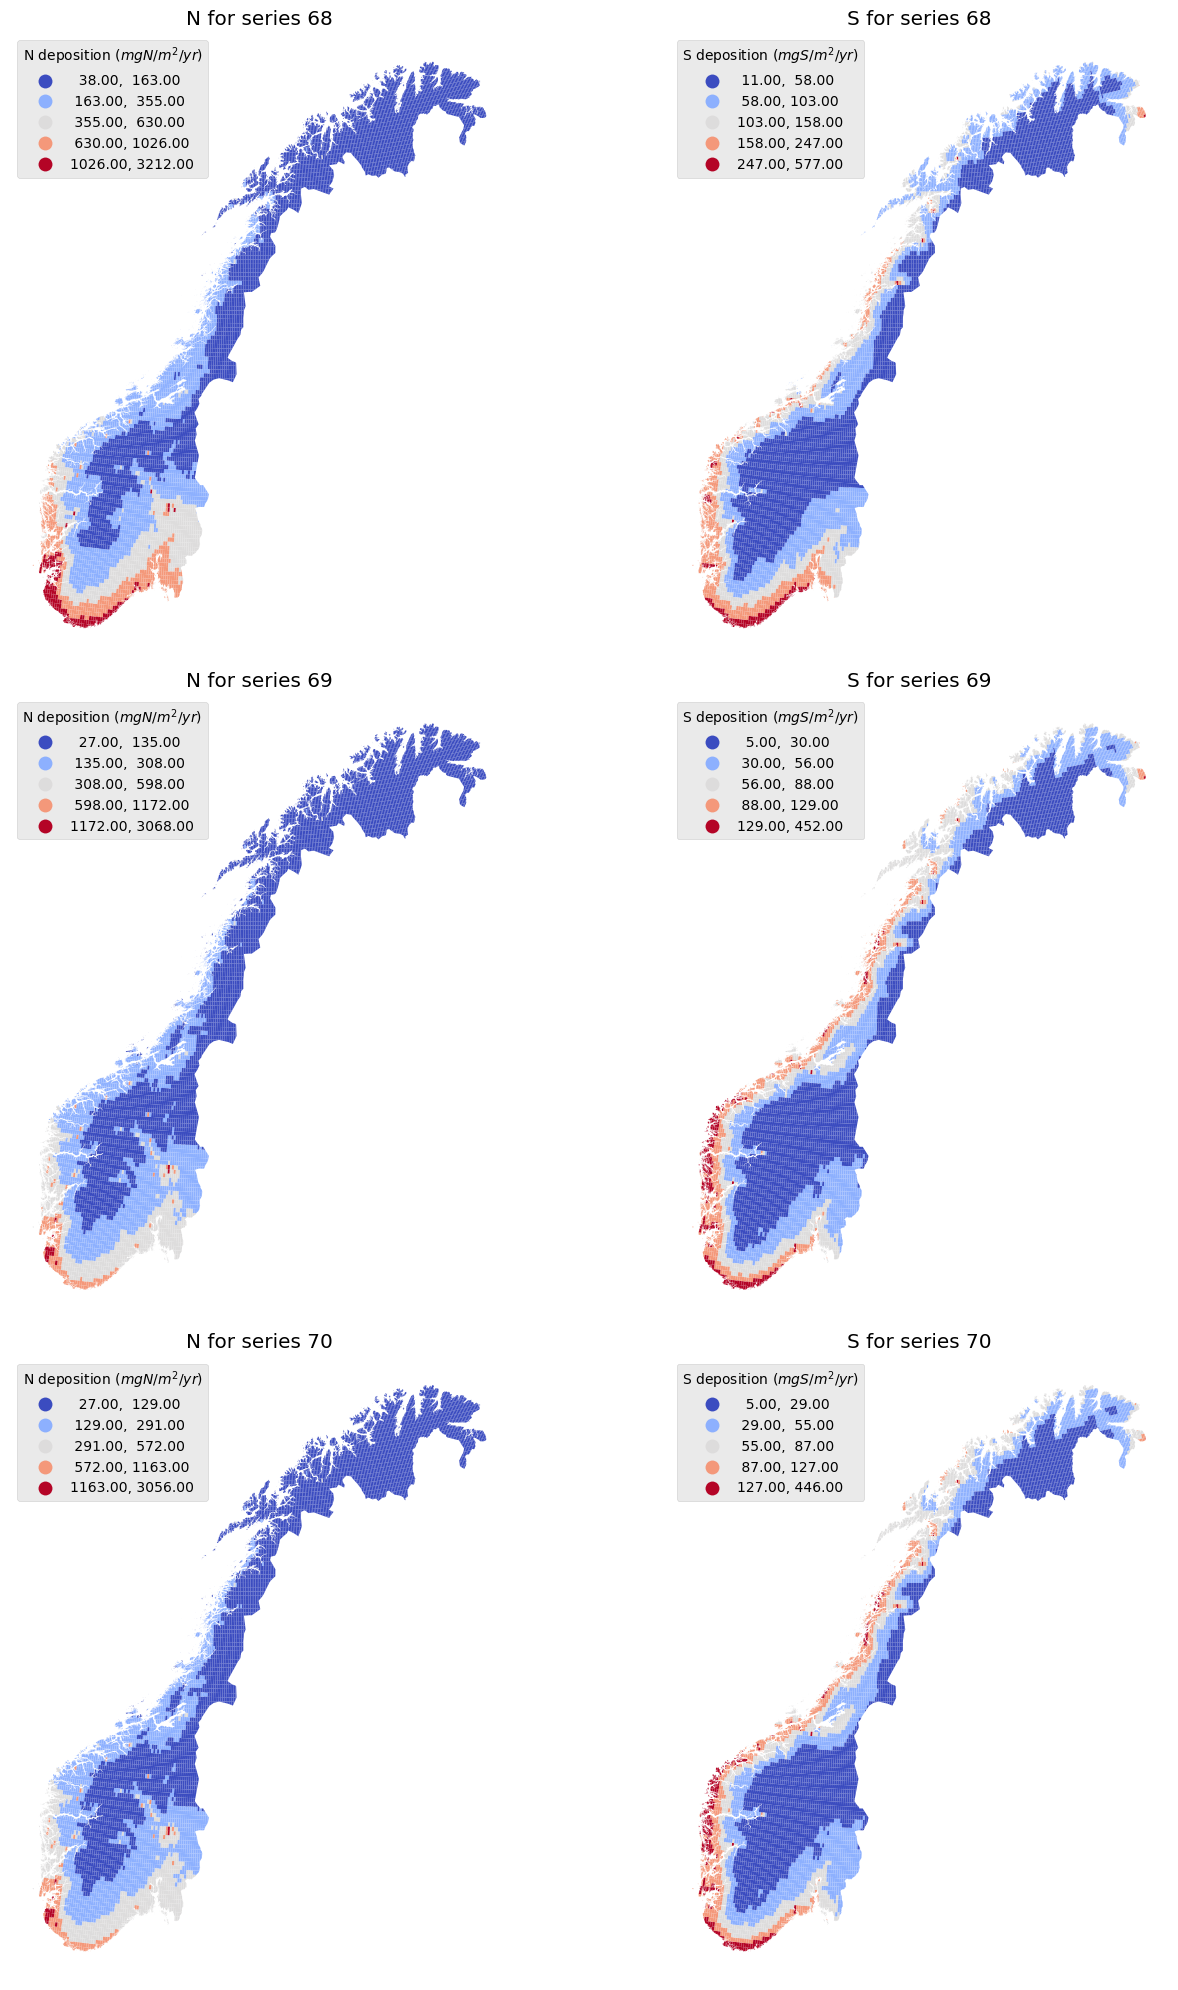

In [6]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 20))

for idx, series_id in enumerate([68, 69, 70]):
    # Get dep data from database
    n_gdf = cl.extract_deposition_as_gdf(series_id, "nitrogen", eng)
    s_gdf = cl.extract_deposition_as_gdf(series_id, "sulphur", eng)

    # Plot
    n_gdf.plot(
        column="ndep_mgpm2pyr",
        cmap="coolwarm",
        scheme="fisher_jenks",
        edgecolor=None,
        legend=True,
        legend_kwds={"loc": "upper left", "title": "N deposition ($mgN/m^2/yr$)"},
        ax=axes[idx, 0],
    )
    axes[idx, 0].set_axis_off()
    axes[idx, 0].set_title(f"N for series {series_id}")

    s_gdf.plot(
        column="sdep_mgpm2pyr",
        cmap="coolwarm",
        scheme="fisher_jenks",
        edgecolor=None,
        legend=True,
        legend_kwds={"loc": "upper left", "title": "S deposition ($mgS/m^2/yr$)"},
        ax=axes[idx, 1],
    )
    axes[idx, 1].set_axis_off()
    axes[idx, 1].set_title(f"S for series {series_id}")

plt.tight_layout()